In [1]:
import pandas as pd
import numpy as np

# Load dataset with correct encoding
df = pd.read_csv("Online Retail.csv", encoding="latin1")

# Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [2]:
#!python -m ipykernel install --user --name ca2-ml --display-name "CA2 ML (.venv)"

In [3]:
# Check number of rows and columns
print("Shape:", df.shape)

Shape: (541909, 8)


In [4]:
# Check column names
print(df.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


In [5]:
# Check data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [6]:
# Count missing values
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
# Basic statistical information
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [8]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [9]:
# Make a copy
data = df.copy()

# Convert InvoiceDate to datetime
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

# Remove transactions without CustomerID
data = data.dropna(subset=['CustomerID'])

# Remove cancelled/return transactions
data = data[data['Quantity'] > 0]

# Remove invalid prices
data = data[data['UnitPrice'] > 0]

# Check the result
print("Shape after cleaning:", data.shape)

Shape after cleaning: (397884, 8)


In [10]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [11]:
print("Date range:")
print(data['InvoiceDate'].min())
print(data['InvoiceDate'].max())

Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00


In [12]:
data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [13]:
data['TotalAmount'] = data['Quantity'] * data['UnitPrice']

data[['Quantity', 'UnitPrice', 'TotalAmount']].head()

,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [14]:
print(data['InvoiceDate'].min())
print(data['InvoiceDate'].max())

2010-12-01 08:26:00
2011-12-09 12:50:00


In [15]:
customer_data = data.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (data['InvoiceDate'].max() - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalAmount', 'sum'),
    TotalProducts=('Quantity', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean')
).reset_index()

In [16]:
customer_data.head()

,CustomerID,Recency,Frequency,Monetary,TotalProducts,AverageOrderValue
0,12346.0,325,1,77183.60,74215,77183.600000
1,12347.0,1,7,4310.00,2458,23.681319
2,12348.0,74,4,1797.24,2341,57.975484
3,12349.0,18,1,1757.55,631,24.076027
4,12350.0,309,1,334.40,197,19.670588


In [17]:
print("Number of customers:", customer_data.shape[0])
print("Number of features:", customer_data.shape[1])

Number of customers: 4338
Number of features: 6


In [18]:
print("Start Date:", data['InvoiceDate'].min())
print("End Date:", data['InvoiceDate'].max())

Start Date: 2010-12-01 08:26:00
End Date: 2011-12-09 12:50:00


In [19]:
cutoff_date = pd.Timestamp('2011-09-01')

In [20]:
cutoff_date = pd.Timestamp('2011-09-01')

historical_data = data[data['InvoiceDate'] < cutoff_date].copy()

future_data = data[data['InvoiceDate'] >= cutoff_date].copy()

print("Historical data:", historical_data.shape)
print("Future data:", future_data.shape)

Historical data: (226467, 9)
Future data: (171417, 9)


In [21]:
reference_date = historical_data['InvoiceDate'].max()

customer_features = historical_data.groupby('CustomerID').agg(
    Recency=('InvoiceDate', 
             lambda x: (reference_date - x.max()).days),

    Frequency=('InvoiceNo', 'nunique'),

    Monetary=('TotalAmount', 'sum'),

    TotalProducts=('Quantity', 'sum'),

    AverageOrderValue=('TotalAmount', 'mean')
).reset_index()

In [22]:
customer_features.head()

,CustomerID,Recency,Frequency,Monetary,TotalProducts,AverageOrderValue
0,12346.0,225,1,77183.60,74215,77183.600000
1,12347.0,29,5,2790.86,1590,22.506935
2,12348.0,148,3,1487.24,2124,53.115714
3,12350.0,210,1,334.40,197,19.670588
4,12352.0,162,5,1561.81,254,41.100263


In [23]:
future_customers = future_data['CustomerID'].unique()

customer_features['PurchasedAgain'] = (
    customer_features['CustomerID']
    .isin(future_customers)
    .astype(int)
)

In [24]:
print(customer_features['PurchasedAgain'].value_counts())

PurchasedAgain
1    1952
0    1365
Name: count, dtype: int64


In [25]:
print(customer_features['PurchasedAgain'].value_counts(normalize=True) * 100)

PurchasedAgain
1    58.848357
0    41.151643
Name: proportion, dtype: float64


In [26]:
ml_data = customer_features.copy()

In [27]:
ml_data.head()

,CustomerID,Recency,Frequency,Monetary,TotalProducts,AverageOrderValue,PurchasedAgain
0,12346.0,225,1,77183.60,74215,77183.600000,0
1,12347.0,29,5,2790.86,1590,22.506935,1
2,12348.0,148,3,1487.24,2124,53.115714,1
3,12350.0,210,1,334.40,197,19.670588,0
4,12352.0,162,5,1561.81,254,41.100263,1


In [28]:
print(ml_data.shape)

(3317, 7)


In [29]:
print("Shape:", ml_data.shape)
print("\nColumns:")
print(ml_data.columns)

print("\nMissing Values:")
print(ml_data.isnull().sum())

Shape: (3317, 7)

Columns:
Index(['CustomerID', 'Recency', 'Frequency', 'Monetary', 'TotalProducts',
       'AverageOrderValue', 'PurchasedAgain'],
      dtype='str')

Missing Values:
CustomerID           0
Recency              0
Frequency            0
Monetary             0
TotalProducts        0
AverageOrderValue    0
PurchasedAgain       0
dtype: int64


In [30]:
ml_data.describe()

,CustomerID,Recency,Frequency,Monetary,TotalProducts,AverageOrderValue,PurchasedAgain
count,3317.000000,3317.000000,3317.000000,3317.000000,3317.000000,3317.000000,3317.000000
mean,15284.195659,92.106723,3.440760,1579.511776,926.304191,62.658017,0.588484
std,1724.184899,76.683833,5.586463,5976.600001,3735.594440,1365.241424,0.492183
min,12346.000000,0.000000,1.000000,2.900000,1.000000,1.450000,0.000000
25%,13799.000000,27.000000,1.000000,261.360000,129.000000,12.725217,0.000000
50%,15245.000000,72.000000,2.000000,555.650000,306.000000,17.800000,1.000000
75%,16770.000000,145.000000,4.000000,1355.110000,771.000000,25.524348,1.000000
max,18287.000000,273.000000,127.000000,176355.940000,126731.000000,77183.600000,1.000000


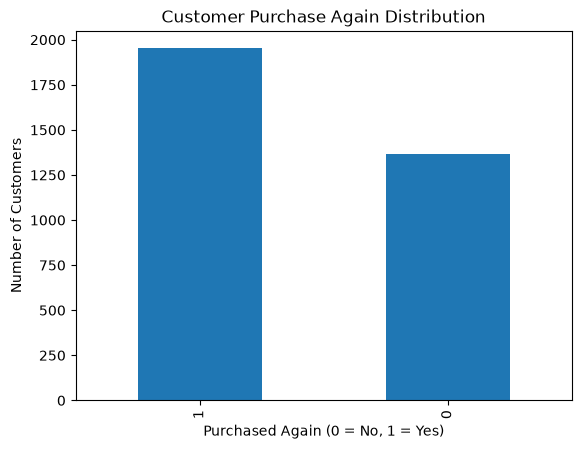

In [31]:
import matplotlib.pyplot as plt

ml_data['PurchasedAgain'].value_counts().plot(kind='bar')

plt.title('Customer Purchase Again Distribution')
plt.xlabel('Purchased Again (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()

In [32]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [33]:
print(
    ml_data['PurchasedAgain']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

PurchasedAgain
1    58.85
0    41.15
Name: proportion, dtype: float64


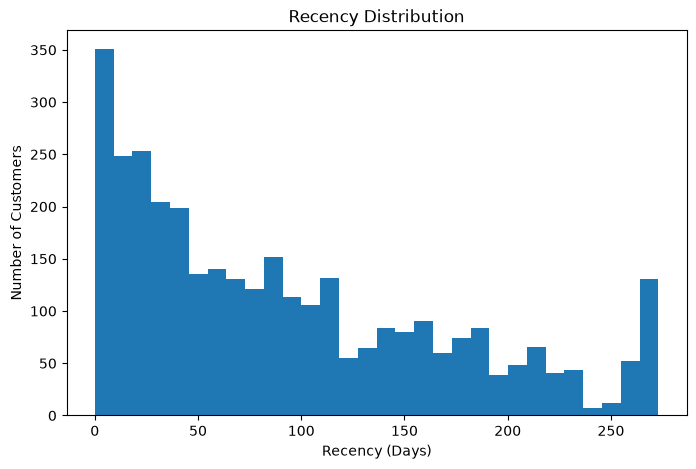

In [34]:
plt.figure(figsize=(8,5))

plt.hist(ml_data['Recency'], bins=30)

plt.title('Recency Distribution')
plt.xlabel('Recency (Days)')
plt.ylabel('Number of Customers')

plt.show()

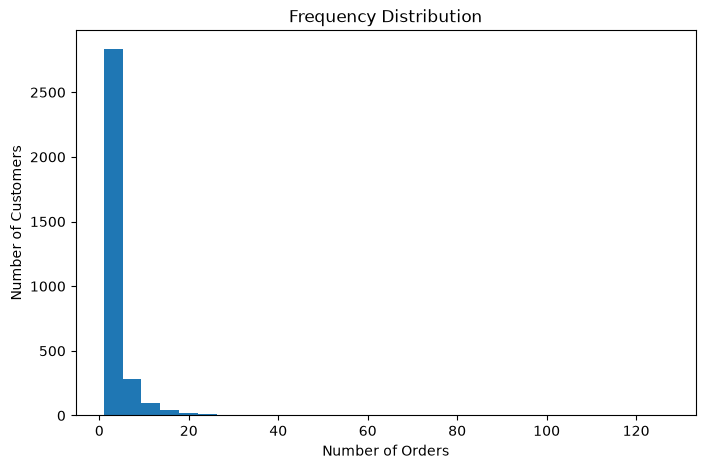

In [35]:
plt.figure(figsize=(8,5))

plt.hist(ml_data['Frequency'], bins=30)

plt.title('Frequency Distribution')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.show()

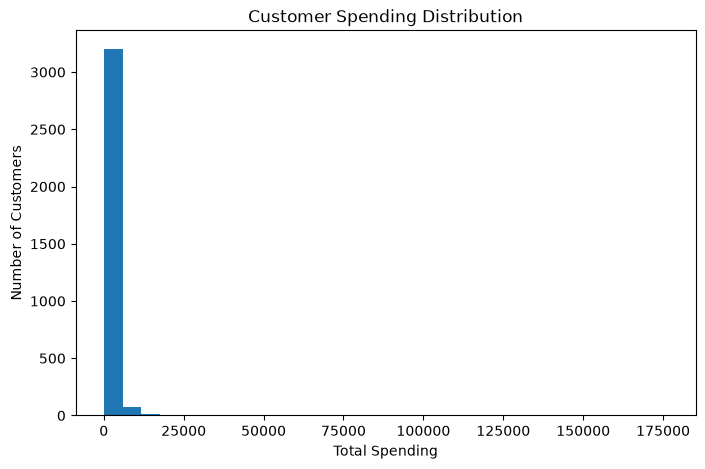

In [36]:
plt.figure(figsize=(8,5))

plt.hist(ml_data['Monetary'], bins=30)

plt.title('Customer Spending Distribution')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')

plt.show()

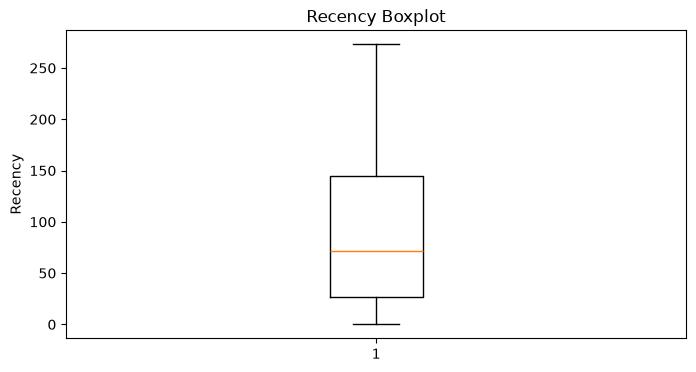

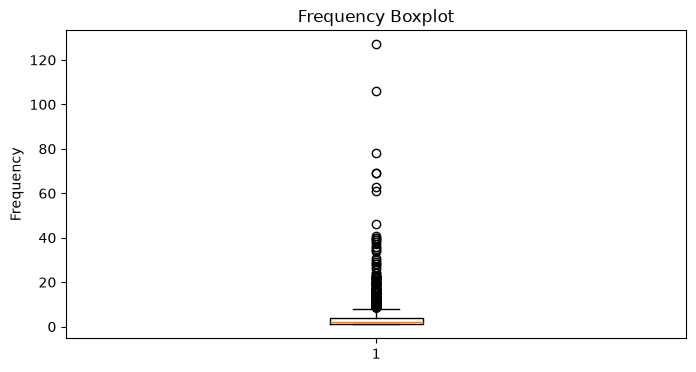

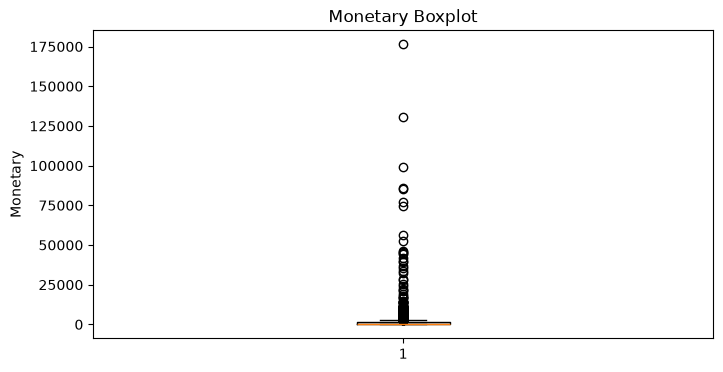

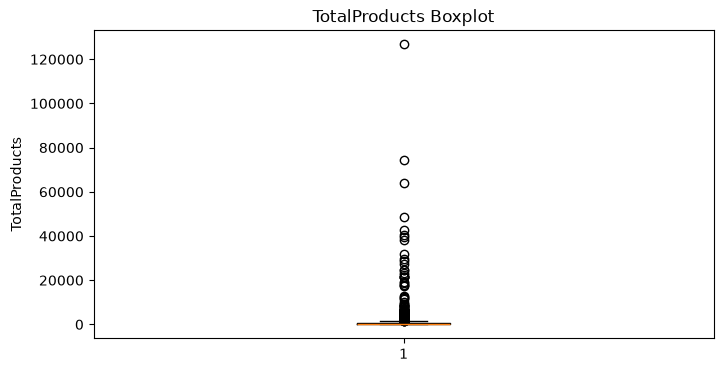

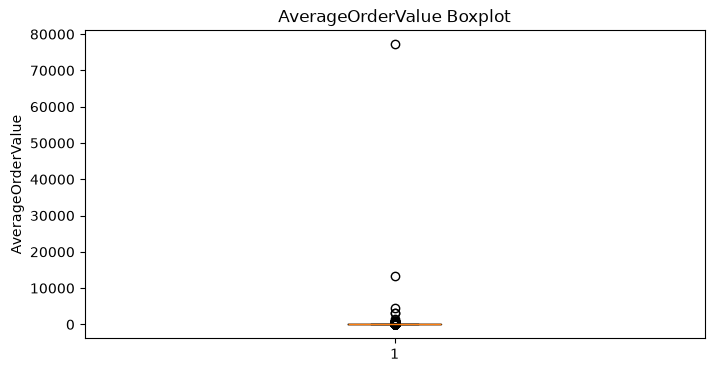

In [37]:
features = [
    'Recency',
    'Frequency',
    'Monetary',
    'TotalProducts',
    'AverageOrderValue'
]

for feature in features:
    plt.figure(figsize=(8,4))
    plt.boxplot(ml_data[feature].dropna())
    plt.title(f'{feature} Boxplot')
    plt.ylabel(feature)
    plt.show()

In [38]:
correlation = ml_data[
    ['Recency',
     'Frequency',
     'Monetary',
     'TotalProducts',
     'AverageOrderValue',
     'PurchasedAgain']
].corr()

print(correlation)

                    Recency  Frequency  Monetary  TotalProducts  \
Recency            1.000000  -0.320706 -0.159618      -0.149933   
Frequency         -0.320706   1.000000  0.531977       0.498248   
Monetary          -0.159618   0.531977  1.000000       0.918036   
TotalProducts     -0.149933   0.498248  0.918036       1.000000   
AverageOrderValue  0.030233  -0.004128  0.254766       0.349362   
PurchasedAgain    -0.308399   0.245421  0.122712       0.115017   

                   AverageOrderValue  PurchasedAgain  
Recency                     0.030233       -0.308399  
Frequency                  -0.004128        0.245421  
Monetary                    0.254766        0.122712  
TotalProducts               0.349362        0.115017  
AverageOrderValue           1.000000       -0.026801  
PurchasedAgain             -0.026801        1.000000  


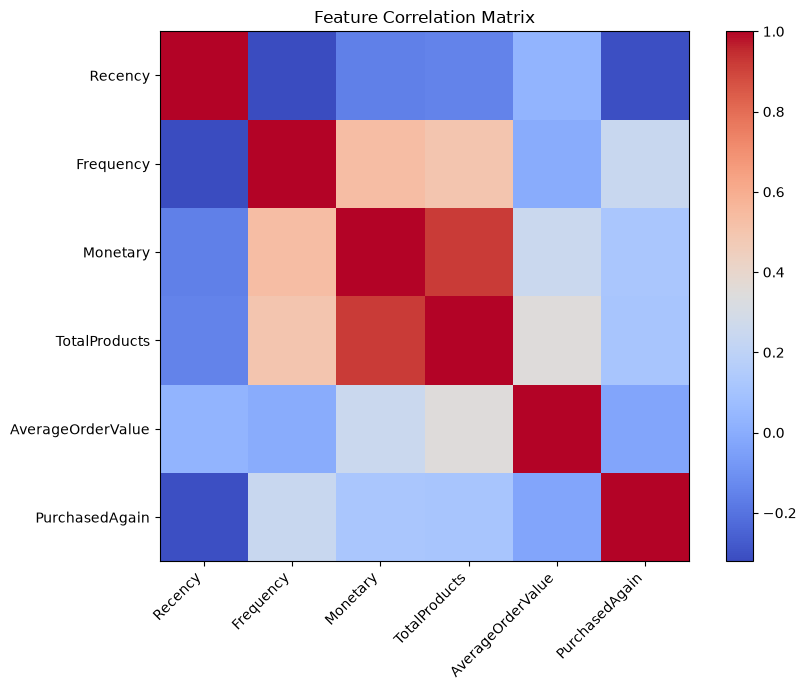

In [39]:
plt.figure(figsize=(9,7))

plt.imshow(correlation, cmap='coolwarm')
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

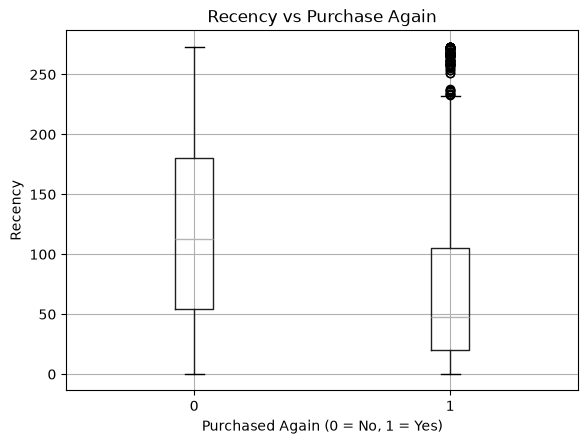

<Figure size 800x500 with 0 Axes>

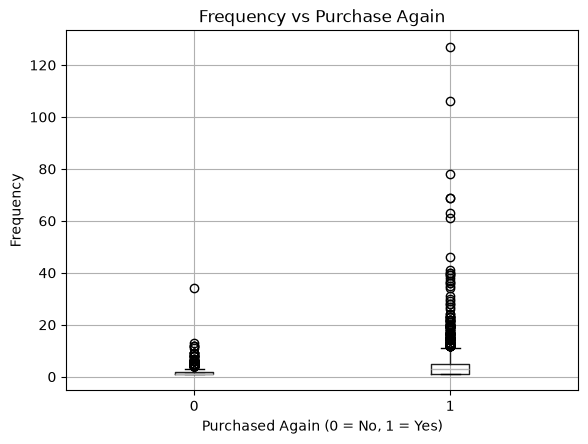

<Figure size 800x500 with 0 Axes>

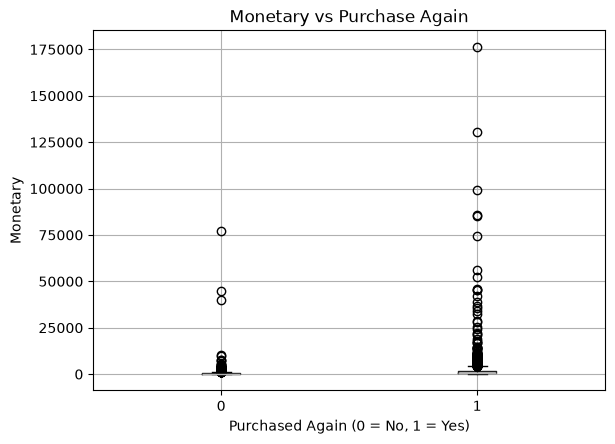

<Figure size 800x500 with 0 Axes>

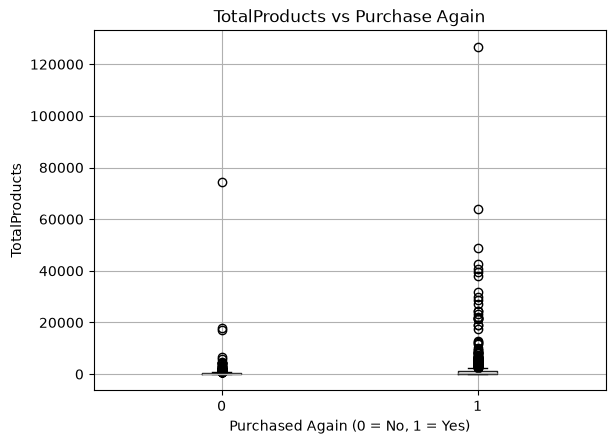

<Figure size 800x500 with 0 Axes>

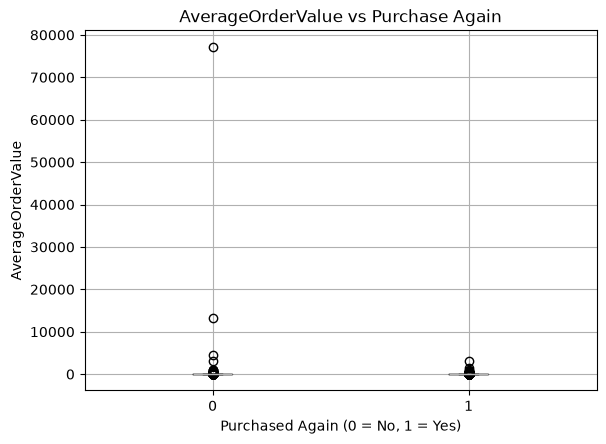

In [40]:
for feature in features:

    plt.figure(figsize=(8,5))

    ml_data.boxplot(
        column=feature,
        by='PurchasedAgain'
    )

    plt.title(f'{feature} vs Purchase Again')
    plt.suptitle('')
    plt.xlabel('Purchased Again (0 = No, 1 = Yes)')
    plt.ylabel(feature)

    plt.show()

In [41]:
features = [
    'Recency',
    'Frequency',
    'Monetary',
    'TotalProducts',
    'AverageOrderValue'
]

X = ml_data[features]
y = ml_data['PurchasedAgain']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3317, 5)
y shape: (3317,)


In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2653, 5)
Testing data: (664, 5)


In [44]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [46]:
scaler.fit_transform(X_train)

array([[-1.01846756, -0.0902012 , -0.02408074,  0.02079828, -0.04070582],
       [-0.82185974, -0.0902012 ,  0.05737673, -0.08279593, -0.03463141],
       [-0.29757221,  0.24613581,  0.11093213,  0.38679859, -0.0403826 ],
       ...,
       [-0.57282316, -0.42653821, -0.20747355, -0.20984543, -0.03087859],
       [-0.88739568,  1.92782084,  0.25664959,  0.43199889, -0.03641974],
       [ 1.11800413, -0.42653821, -0.20447732, -0.2000724 , -0.02688683]],
      shape=(2653, 5))

In [47]:
scaler.transform(X_test)

array([[-0.80875255, -0.42653821, -0.17827106, -0.20935678, -0.02134659],
       [-0.1927147 , -0.2583697 , -0.19127843, -0.1888334 , -0.00769187],
       [-0.28446502, -0.42653821, -0.2373    , -0.19689616, -0.03800893],
       ...,
       [-0.92671724, -0.2583697 , -0.20464721, -0.20251566, -0.03305357],
       [-1.18886101,  2.60049485,  6.21038996,  5.17021247,  0.27254596],
       [ 2.35007984, -0.42653821, -0.21969789, -0.23061314, -0.03569784]],
      shape=(664, 5))

In [48]:
print("Before scaling:")
print(X_train.head())

print("\nAfter scaling:")
print(X_train_scaled[:5])

Before scaling:
      Recency  Frequency  Monetary  TotalProducts  AverageOrderValue
2476       14          3   1496.83           1064           8.804882
623        29          3   2024.25            640          18.073661
2799       69          5   2371.01           2562           9.298078
1814       14          1     85.13             49           2.935517
2494        0          2    425.19            271           7.086500

After scaling:
[[-1.01846756 -0.0902012  -0.02408074  0.02079828 -0.04070582]
 [-0.82185974 -0.0902012   0.05737673 -0.08279593 -0.03463141]
 [-0.29757221  0.24613581  0.11093213  0.38679859 -0.0403826 ]
 [-1.01846756 -0.42653821 -0.24211097 -0.22719258 -0.04455238]
 [-1.2019682  -0.2583697  -0.18959035 -0.17295221 -0.04183199]]


In [49]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
PurchasedAgain
1    1561
0    1092
Name: count, dtype: int64

Testing target distribution:
PurchasedAgain
1    391
0    273
Name: count, dtype: int64


In [50]:
print("Training percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting percentage:")
print(y_test.value_counts(normalize=True) * 100)

Training percentage:
PurchasedAgain
1    58.83905
0    41.16095
Name: proportion, dtype: float64

Testing percentage:
PurchasedAgain
1    58.885542
0    41.114458
Name: proportion, dtype: float64


In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [52]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

In [53]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

In [54]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [55]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

In [56]:
svm_model = SVC(
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

b:\CA2 ML\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [57]:
# 1. Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
logistic_model.fit(X_train_scaled, y_train)
y_pred_logistic = logistic_model.predict(X_test_scaled)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]


# 2. Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]


# 3. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]


# 4. KNN
knn_model = KNeighborsClassifier(
    n_neighbors=5
)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]


# 5. SVM
svm_model = SVC(
    probability=True,
    random_state=42
)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

print("All 5 models trained successfully!")

b:\CA2 ML\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


All 5 models trained successfully!


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [59]:
models_results = {
    "Logistic Regression": (y_test, y_pred_logistic, y_prob_logistic),
    "Decision Tree": (y_test, y_pred_dt, y_prob_dt),
    "Random Forest": (y_test, y_pred_rf, y_prob_rf),
    "KNN": (y_test, y_pred_knn, y_prob_knn),
    "SVM": (y_test, y_pred_svm, y_prob_svm)
}

In [60]:
results = []

for name, (actual, predicted, probability) in models_results.items():

    accuracy = accuracy_score(actual, predicted)
    precision = precision_score(actual, predicted, zero_division=0)
    recall = recall_score(actual, predicted, zero_division=0)
    f1 = f1_score(actual, predicted, zero_division=0)
    auc = roc_auc_score(actual, probability)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.676205,0.714634,0.749361,0.731586,0.734418
1,Decision Tree,0.646084,0.701031,0.695652,0.698331,0.699915
2,Random Forest,0.640060,0.691919,0.700767,0.696315,0.698355
3,KNN,0.646084,0.695980,0.708440,0.702155,0.689530
4,SVM,0.662651,0.701205,0.744246,0.722084,0.720712


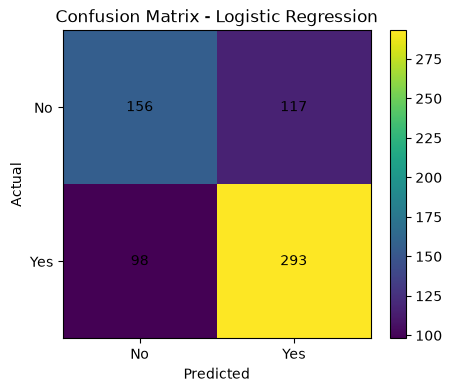

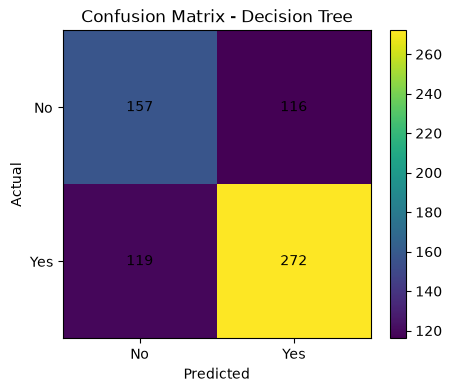

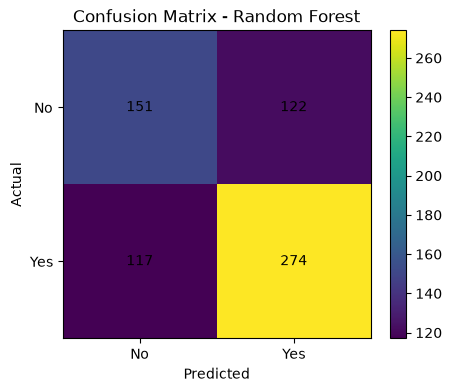

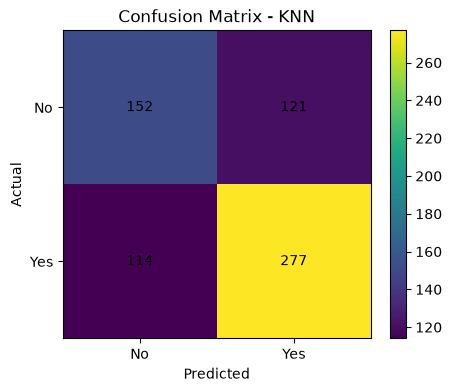

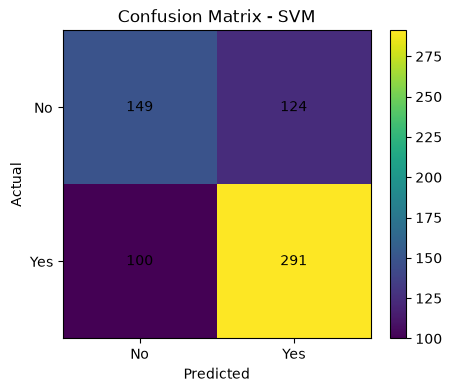

In [61]:
import matplotlib.pyplot as plt

for name, (actual, predicted, probability) in models_results.items():

    cm = confusion_matrix(actual, predicted)

    plt.figure(figsize=(5, 4))
    plt.imshow(cm)

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.xticks([0, 1], ['No', 'Yes'])
    plt.yticks([0, 1], ['No', 'Yes'])

    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j],
                     ha='center',
                     va='center')

    plt.colorbar()
    plt.show()

In [62]:
for name, (actual, predicted, probability) in models_results.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)

    print(classification_report(
        actual,
        predicted,
        target_names=['No Purchase', 'Purchase'],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.61      0.57      0.59       273
    Purchase       0.71      0.75      0.73       391

    accuracy                           0.68       664
   macro avg       0.66      0.66      0.66       664
weighted avg       0.67      0.68      0.67       664


Decision Tree
              precision    recall  f1-score   support

 No Purchase       0.57      0.58      0.57       273
    Purchase       0.70      0.70      0.70       391

    accuracy                           0.65       664
   macro avg       0.63      0.64      0.64       664
weighted avg       0.65      0.65      0.65       664


Random Forest
              precision    recall  f1-score   support

 No Purchase       0.56      0.55      0.56       273
    Purchase       0.69      0.70      0.70       391

    accuracy                           0.64       664
   macro avg       0.63      0.63      0.63       664
weighted avg       0.64

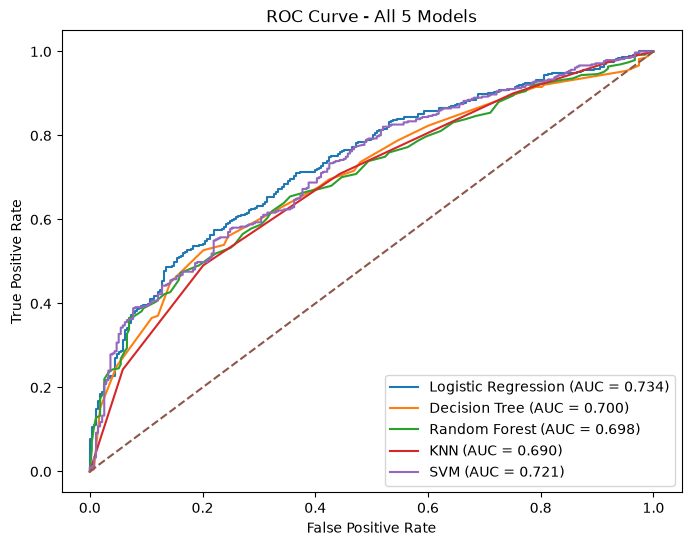

In [63]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, (actual, predicted, probability) in models_results.items():

    fpr, tpr, thresholds = roc_curve(actual, probability)

    auc = roc_auc_score(actual, probability)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc:.3f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - All 5 Models')
plt.legend()
plt.show()

In [64]:
results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.676205   0.714634  0.749361  0.731586  0.734418
4                  SVM  0.662651   0.701205  0.744246  0.722084  0.720712
1        Decision Tree  0.646084   0.701031  0.695652  0.698331  0.699915
2        Random Forest  0.640060   0.691919  0.700767  0.696315  0.698355
3                  KNN  0.646084   0.695980  0.708440  0.702155  0.689530


In [65]:
results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
)

In [66]:
best_model_name = results_df.iloc[0]['Model']

print("Best Model:", best_model_name)

Best Model: Logistic Regression


In [67]:
best_f1_model = results_df.loc[
    results_df['F1 Score'].idxmax(),
    'Model'
]

print("Best F1 Model:", best_f1_model)

Best F1 Model: Logistic Regression


In [68]:
def predict_customer_tree(
    recency,
    frequency,
    monetary,
    total_products,
    average_order_value
):
    
    new_customer = pd.DataFrame({
        'Recency': [recency],
        'Frequency': [frequency],
        'Monetary': [monetary],
        'TotalProducts': [total_products],
        'AverageOrderValue': [average_order_value]
    })
    
    prediction = rf_model.predict(new_customer)[0]
    probability = rf_model.predict_proba(new_customer)[0][1]
    
    if prediction == 1:
        result = "LIKELY TO PURCHASE"
    else:
        result = "UNLIKELY TO PURCHASE"
    
    print("Prediction:", result)
    print("Purchase Probability:", round(probability * 100, 2), "%")

In [69]:
predict_customer_tree(
    recency=15,
    frequency=12,
    monetary=35000,
    total_products=85,
    average_order_value=2916
)

Prediction: LIKELY TO PURCHASE
Purchase Probability: 53.0 %


In [70]:
def predict_new_customer(
    recency,
    frequency,
    monetary,
    total_products,
    average_order_value
):
    
    new_customer = pd.DataFrame({
        'Recency': [recency],
        'Frequency': [frequency],
        'Monetary': [monetary],
        'TotalProducts': [total_products],
        'AverageOrderValue': [average_order_value]
    })
    
    if best_model_name == "Logistic Regression":
        prediction = logistic_model.predict(
            scaler.transform(new_customer)
        )[0]
        
        probability = logistic_model.predict_proba(
            scaler.transform(new_customer)
        )[0][1]
        
    elif best_model_name == "Decision Tree":
        prediction = dt_model.predict(new_customer)[0]
        probability = dt_model.predict_proba(new_customer)[0][1]
        
    elif best_model_name == "Random Forest":
        prediction = rf_model.predict(new_customer)[0]
        probability = rf_model.predict_proba(new_customer)[0][1]
        
    elif best_model_name == "KNN":
        scaled_customer = scaler.transform(new_customer)
        
        prediction = knn_model.predict(
            scaled_customer
        )[0]
        
        probability = knn_model.predict_proba(
            scaled_customer
        )[0][1]
        
    elif best_model_name == "SVM":
        scaled_customer = scaler.transform(new_customer)
        
        prediction = svm_model.predict(
            scaled_customer
        )[0]
        
        probability = svm_model.predict_proba(
            scaled_customer
        )[0][1]
    
    if prediction == 1:
        result = "LIKELY TO PURCHASE"
    else:
        result = "UNLIKELY TO PURCHASE"
    
    print("Best Model:", best_model_name)
    print("Prediction:", result)
    print("Purchase Probability:", round(probability * 100, 2), "%")

In [71]:
segmentation_features = [
    'Recency',
    'Frequency',
    'Monetary',
    'TotalProducts',
    'AverageOrderValue'
]

X_cluster = ml_data[segmentation_features].copy()

print(X_cluster.head())

   Recency  Frequency  Monetary  TotalProducts  AverageOrderValue
0      225          1  77183.60          74215       77183.600000
1       29          5   2790.86           1590          22.506935
2      148          3   1487.24           2124          53.115714
3      210          1    334.40            197          19.670588
4      162          5   1561.81            254          41.100263


In [72]:
segmentation_features = [
    'Recency',
    'Frequency',
    'Monetary',
    'TotalProducts',
    'AverageOrderValue'
]

X_cluster = ml_data[segmentation_features].copy()

print(X_cluster.head())

   Recency  Frequency  Monetary  TotalProducts  AverageOrderValue
0      225          1  77183.60          74215       77183.600000
1       29          5   2790.86           1590          22.506935
2      148          3   1487.24           2124          53.115714
3      210          1    334.40            197          19.670588
4      162          5   1561.81            254          41.100263


In [73]:
from sklearn.preprocessing import StandardScaler

cluster_scaler = StandardScaler()

X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)

In [74]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_cluster_scaled)
    
    inertia.append(kmeans.inertia_)

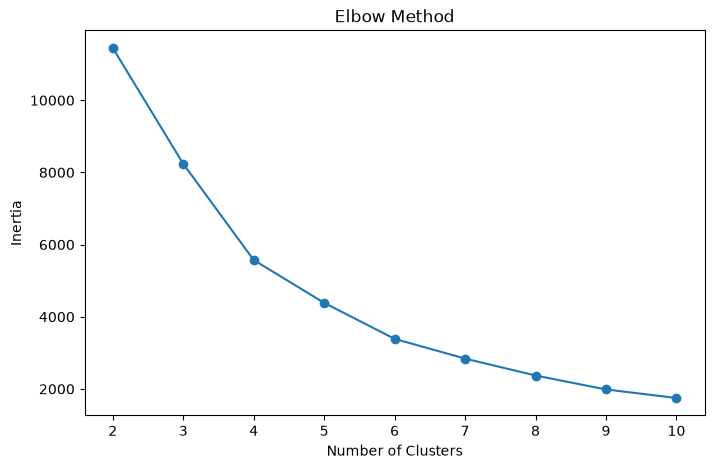

In [75]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.show()

In [76]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

ml_data['Cluster'] = kmeans.fit_predict(X_cluster_scaled)

print(ml_data['Cluster'].value_counts())

Cluster
1    2143
0    1143
4      25
3       5
2       1
Name: count, dtype: int64


In [77]:
cluster_summary = ml_data.groupby('Cluster')[
    [
        'Recency',
        'Frequency',
        'Monetary',
        'TotalProducts',
        'AverageOrderValue'
    ]
].mean()

cluster_summary

,Recency,Frequency,Monetary,TotalProducts,AverageOrderValue
Cluster,,,,,
0,183.100612,1.426072,453.710788,252.849519,35.830632
1,44.589827,4.001867,1523.410458,876.796547,36.997711
2,225.000000,1.000000,77183.600000,74215.000000,77183.600000
3,13.200000,27.200000,115362.314000,58576.000000,334.426451
4,15.480000,42.800000,32079.414000,21498.960000,349.616078


In [78]:
cluster_summary = ml_data.groupby('Cluster')[
    [
        'Recency',
        'Frequency',
        'Monetary',
        'TotalProducts',
        'AverageOrderValue'
    ]
].mean()

print(cluster_summary)


            Recency  Frequency       Monetary  TotalProducts  \
Cluster                                                        
0        183.100612   1.426072     453.710788     252.849519   
1         44.589827   4.001867    1523.410458     876.796547   
2        225.000000   1.000000   77183.600000   74215.000000   
3         13.200000  27.200000  115362.314000   58576.000000   
4         15.480000  42.800000   32079.414000   21498.960000   

         AverageOrderValue  
Cluster                     
0                35.830632  
1                36.997711  
2             77183.600000  
3               334.426451  
4               349.616078  


In [79]:
print(ml_data['Cluster'].value_counts().sort_index())

Cluster
0    1143
1    2143
2       1
3       5
4      25
Name: count, dtype: int64


In [82]:
cluster_names = {
    0: 'High Value',
    1: 'Regular',
    2: 'At Risk',
    3: 'Loyal',
    4: 'Occasional'
}

ml_data['CustomerSegment'] = ml_data['Cluster'].map(cluster_names)

In [83]:
ml_data[
    ['CustomerID', 'Cluster', 'CustomerSegment']
].head(10)

,CustomerID,Cluster,CustomerSegment
0,12346.0,2,At Risk
1,12347.0,1,Regular
2,12348.0,0,High Value
3,12350.0,0,High Value
4,12352.0,0,High Value
5,12353.0,1,Regular
6,12354.0,0,High Value
7,12355.0,0,High Value
8,12356.0,0,High Value
9,12358.0,1,Regular


In [84]:
ml_data[
    ['CustomerID', 'Cluster', 'CustomerSegment']
].head(10)

,CustomerID,Cluster,CustomerSegment
0,12346.0,2,At Risk
1,12347.0,1,Regular
2,12348.0,0,High Value
3,12350.0,0,High Value
4,12352.0,0,High Value
5,12353.0,1,Regular
6,12354.0,0,High Value
7,12355.0,0,High Value
8,12356.0,0,High Value
9,12358.0,1,Regular


In [85]:
def final_customer_prediction(
    recency,
    frequency,
    monetary,
    total_products,
    average_order_value
):
    
    new_customer = pd.DataFrame({
        'Recency': [recency],
        'Frequency': [frequency],
        'Monetary': [monetary],
        'TotalProducts': [total_products],
        'AverageOrderValue': [average_order_value]
    })
    
    # -------------------------
    # PURCHASE PREDICTION
    # -------------------------
    
    if best_model_name == "Logistic Regression":
        
        scaled = scaler.transform(new_customer)
        
        prediction = logistic_model.predict(scaled)[0]
        probability = logistic_model.predict_proba(scaled)[0][1]
        
    elif best_model_name == "Decision Tree":
        
        prediction = dt_model.predict(new_customer)[0]
        probability = dt_model.predict_proba(new_customer)[0][1]
        
    elif best_model_name == "Random Forest":
        
        prediction = rf_model.predict(new_customer)[0]
        probability = rf_model.predict_proba(new_customer)[0][1]
        
    elif best_model_name == "KNN":
        
        scaled = scaler.transform(new_customer)
        
        prediction = knn_model.predict(scaled)[0]
        probability = knn_model.predict_proba(scaled)[0][1]
        
    elif best_model_name == "SVM":
        
        scaled = scaler.transform(new_customer)
        
        prediction = svm_model.predict(scaled)[0]
        probability = svm_model.predict_proba(scaled)[0][1]
    
    
    # -------------------------
    # CUSTOMER SEGMENT
    # -------------------------
    
    scaled_cluster = cluster_scaler.transform(new_customer)
    
    cluster = kmeans.predict(scaled_cluster)[0]
    
    segment = cluster_names.get(
        cluster,
        f"Cluster {cluster}"
    )
    
    
    # -------------------------
    # FINAL RESULT
    # -------------------------
    
    if prediction == 1:
        purchase_result = "LIKELY TO PURCHASE"
    else:
        purchase_result = "UNLIKELY TO PURCHASE"
    
    
    print("====================================")
    print("       CUSTOMER ANALYTICS")
    print("====================================")
    
    print("Best Model:", best_model_name)
    print("Purchase Prediction:", purchase_result)
    print("Purchase Probability:",
          round(probability * 100, 2), "%")
    
    print("------------------------------------")
    
    print("Cluster:", cluster)
    print("Customer Segment:", segment)
    
    print("====================================")

In [86]:
pip install streamlit

   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ------------- -------------------------- 3.7/10.5 MB 19.4 MB/s eta 0:00:01
   ---------------- ----------------------- 4.5/10.5 MB 12.0 MB/s eta 0:00:01
   ------------------ --------------------- 5.0/10.5 MB 8.5 MB/s eta 0:00:01
   -------------------- ------------------- 5.5/10.5 MB 6.8 MB/s eta 0:00:01
   ------------------------ --------------- 6.6/10.5 MB 6.4 MB/s eta 0:00:01
   ---------------------------- ----------- 7.6/10.5 MB 6.3 MB/s eta 0:00:01
   -------------------------------- ------- 8.7/10.5 MB 6.1 MB/s eta 0:00:01
   ------------------------------------- -- 10.0/10.5 MB 6.0 MB/s eta 0:00:01
   ---------------------------------------- 10.5/10.5 MB 5.7 MB/s  0:00:01
   ---------------------------------------- 0.0/797.6 kB ? eta -:--:--
   ---------------------------------------- 797.6/797.6 kB 5.0 MB/s  0:00:00
   ---------------------------------------- 0.0/28.6 MB ? eta -:--:--
   -- ------------

In [91]:
!streamlit --version

Streamlit, version 1.62.0


In [92]:
import joblib

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "KNN": knn_model,
    "SVM": svm_model
}

joblib.dump(models, "models.pkl")

joblib.dump(scaler, "scaler.pkl")
joblib.dump(cluster_scaler, "cluster_scaler.pkl")
joblib.dump(kmeans, "kmeans.pkl")

print("Models saved successfully!")

Models saved successfully!


In [93]:
joblib.dump(best_model_name, "best_model_name.pkl")

['best_model_name.pkl']